In [3]:
import sys
import pandas
import sklearn

print("Python:", sys.version)
print("Interpreter:", sys.executable)
print("Pandas:", pandas.__version__)
print("Scikit-learn:", sklearn.__version__)
print("Jupyter is working successfully!")

Python: 3.13.6 (tags/v3.13.6:4e66535, Aug  6 2025, 14:36:00) [MSC v.1944 64 bit (AMD64)]
Interpreter: c:\Program Files\Python313\python.exe
Pandas: 2.3.3
Scikit-learn: 1.8.0
Jupyter is working successfully!


In [5]:

import pandas as pd

df = pd.read_csv("data.csv")

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)
display(df.head())


Dataset loaded successfully!
Dataset Shape: (569, 33)


,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN


In [6]:

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Remove unnecessary columns
df_clean = df.drop(columns=["id", "Unnamed: 32"], errors="ignore")

# Convert diagnosis to numerical values
df_clean["diagnosis"] = df_clean["diagnosis"].map({"M": 1, "B": 0})

# Separate features and target
X = df_clean.drop("diagnosis", axis=1)
y = df_clean["diagnosis"]

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Standardize features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])
print("Number of features:", X.shape[1])


Training samples: 455
Testing samples: 114
Number of features: 30


In [7]:

from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, precision_score,
    recall_score, f1_score
)
import pandas as pd

# Define SVM kernels
kernels = ["linear", "poly", "rbf", "sigmoid"]

results = []
predictions = {}

# Train and evaluate each SVM classifier
for kernel in kernels:
    model = SVC(kernel=kernel, C=1)

    model.fit(X_train_scaled, y_train)

    y_pred = model.predict(X_test_scaled)
    predictions[kernel] = y_pred

    results.append({
        "Kernel": kernel,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1 Score": f1_score(y_test, y_pred)
    })

# Display performance comparison
results_df = pd.DataFrame(results)

print("SVM KERNEL PERFORMANCE COMPARISON")
display(results_df.round(4))


SVM KERNEL PERFORMANCE COMPARISON


,Kernel,Accuracy,Precision,Recall,F1 Score
0,linear,0.9649,1.0000,0.9048,0.9500
1,poly,0.8860,1.0000,0.6905,0.8169
2,rbf,0.9737,1.0000,0.9286,0.9630
3,sigmoid,0.9474,0.9737,0.8810,0.9250


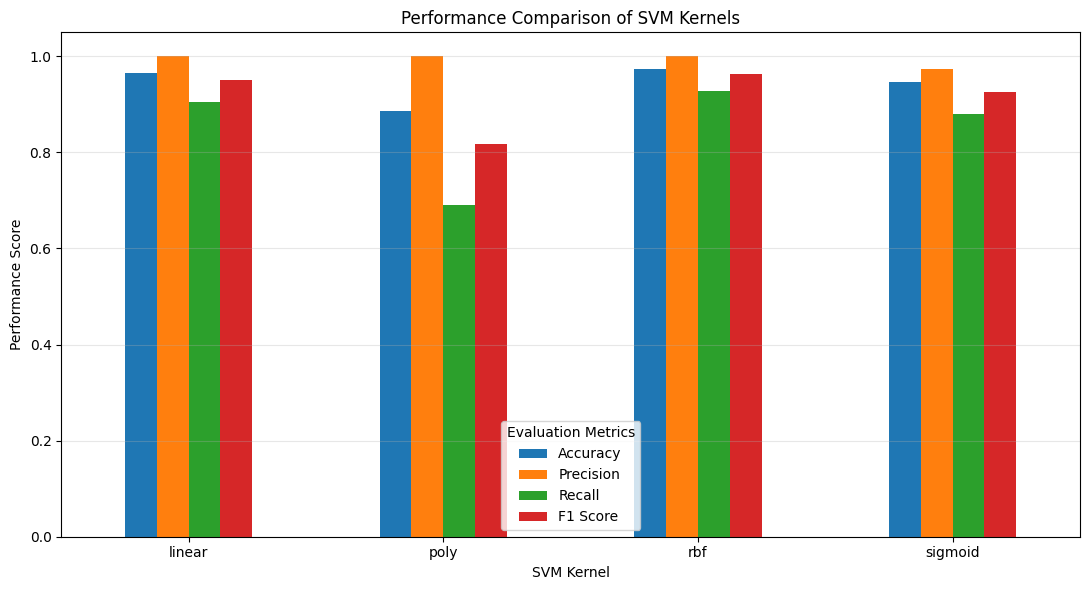

In [8]:

import matplotlib.pyplot as plt

results_df.set_index("Kernel")[
    ["Accuracy", "Precision", "Recall", "F1 Score"]
].plot(kind="bar", figsize=(11, 6))

plt.title("Performance Comparison of SVM Kernels")
plt.xlabel("SVM Kernel")
plt.ylabel("Performance Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.legend(title="Evaluation Metrics")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


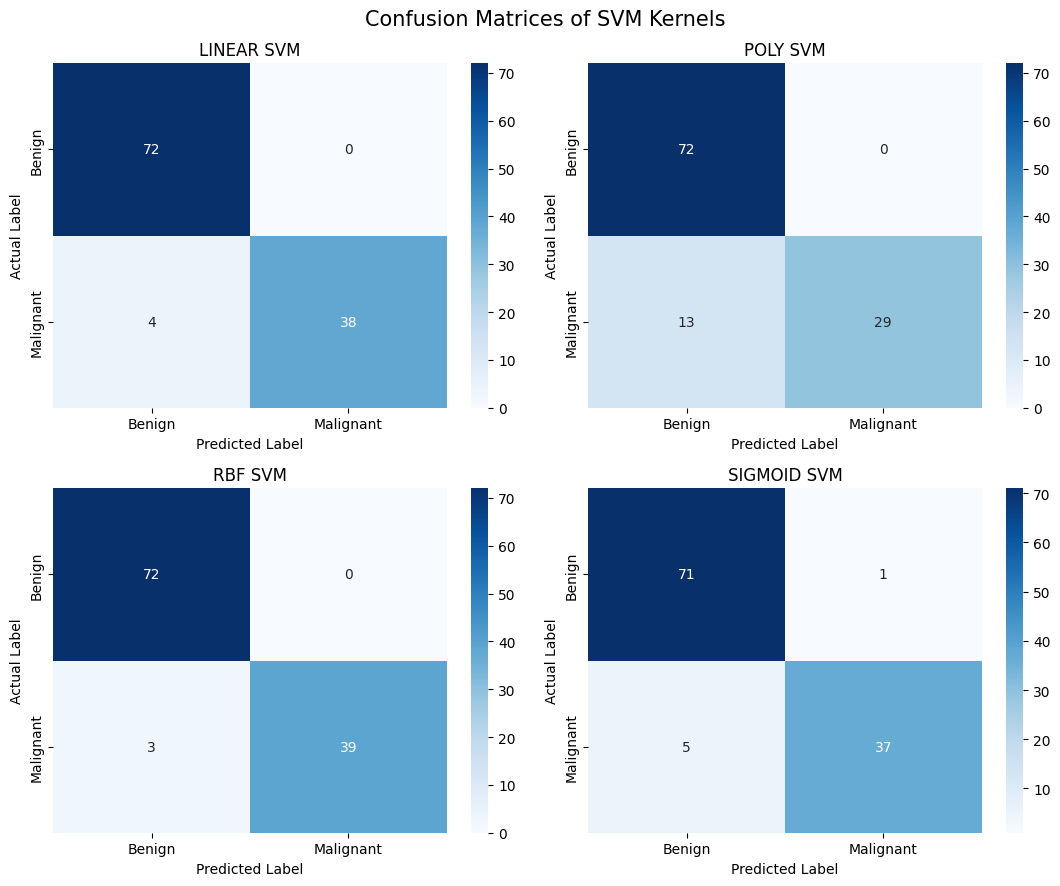

In [9]:

import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

fig, axes = plt.subplots(2, 2, figsize=(11, 9))

for ax, kernel in zip(axes.flatten(), kernels):
    cm = confusion_matrix(
        y_test, predictions[kernel], labels=[0, 1]
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        ax=ax,
        xticklabels=["Benign", "Malignant"],
        yticklabels=["Benign", "Malignant"]
    )

    ax.set_title(f"{kernel.upper()} SVM")
    ax.set_xlabel("Predicted Label")
    ax.set_ylabel("Actual Label")

plt.suptitle("Confusion Matrices of SVM Kernels", fontsize=15)
plt.tight_layout()
plt.show()
